In [1]:
import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 

import sqlite3
import pandas as pd
from os.path import basename

import glob

In [2]:
# Define a report element that we want to run. Needs branch maf-proto of rubin_sim to run
class CountsTimeElement(splat.BaseReportElement):
    def compute_elements(self,visits_df=None, visits_array=None, nside=32, band=None):
        metrics = []
        infos = []
        times = np.arange(3653)
        metrics.append(splat.AccumulateCountMetric(times))
        info = {"data_source": self.run_name}
        if band is None:
            info["observations_subset"] = "\nNo ToO, No DDf, expt > 20"
        else:
            info["observations_subset"] =  band + "\nNo ToO, No DDf, expt > 20"

        # Number of visits
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Counts"
        infos.append(temp_info)
       
        is_too = np.array(["ToO" in note for note in visits_array["scheduler_note"]])
        is_ddf = np.array(["DD" in note for note in visits_array["scheduler_note"]])

        if band is None:
            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20))
        else:
            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20) & (visits_array["band"] == band))
        sub_data = visits_array[indx]
        sl = splat.Slicer(nside=nside, missing=0)
        hp_arrays, infos = sl(sub_data, metrics, info=infos)

        return hp_arrays, infos, None


In [3]:
db_files = ['baseline_v5.3.7_10yrs.db', 'three_stripes_v5.3.7_10yrs.db',
            'three_stripes_kr_v5.3.7_10yrs.db',
            'desi_tskr_v5.3.7_10yrs.db',
            'desi_stripes_delayed_v5.3.7_10yrs.db',
            'desi_stripes_v5.3.7_10yrs.db',
            "double_stripes_timing_bands_v5.3.7_10yrs.db",
            "three_stripes_or_v5.3.7_10yrs.db",
            "delay_roll_v5.3.7_10yrs.db"
            ]

In [4]:
data_list = []
info_list = []

u_data_list = []
u_info_list = []
for filename in db_files:
    element = CountsTimeElement(observations=filename)
    hp_arrays, infos, summary = element()
    data_list.append(hp_arrays)
    info_list.append(infos)

    hp_arrays, infos, summary = element(band="u")
    u_data_list.append(hp_arrays)
    u_info_list.append(infos)
    
    

# Year 1
All plots No ToOs, No DDfs, expt > 20. All bands unless marked.

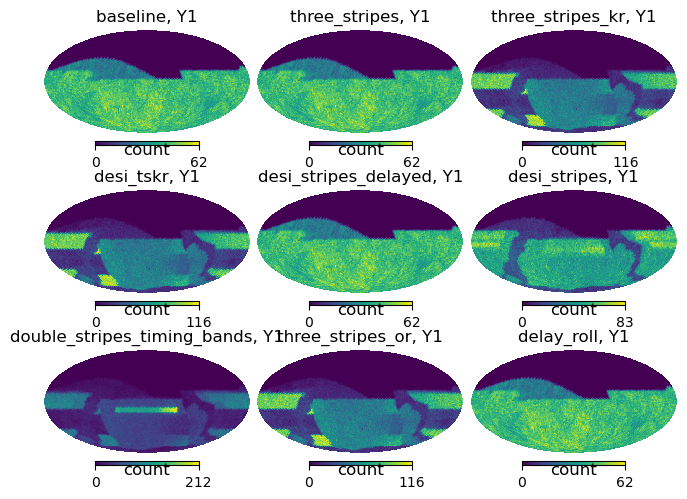

In [5]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y1",
                unit="count", sub=(3,3, i+1))

# Year 2

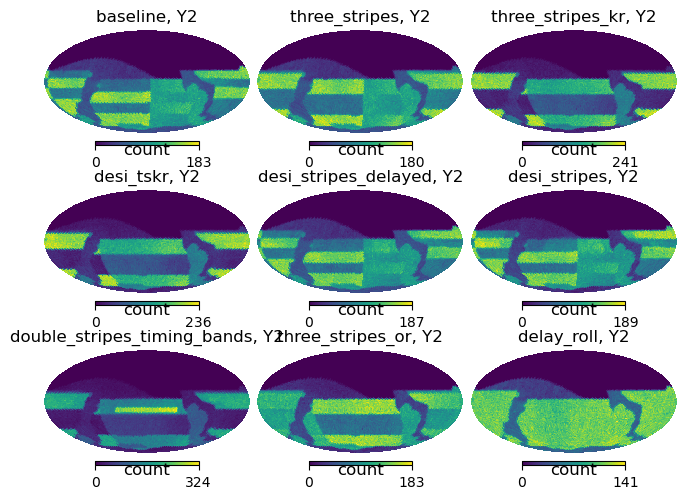

In [6]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*2], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y2",
                unit="count", sub=(3,3, i+1))

# Year 4

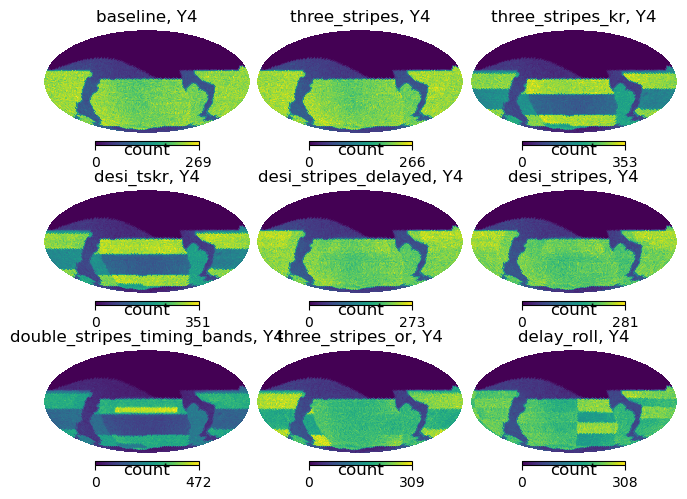

In [7]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*4], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y4" ,
                unit="count", sub=(3,3, i+1))

# Year 10



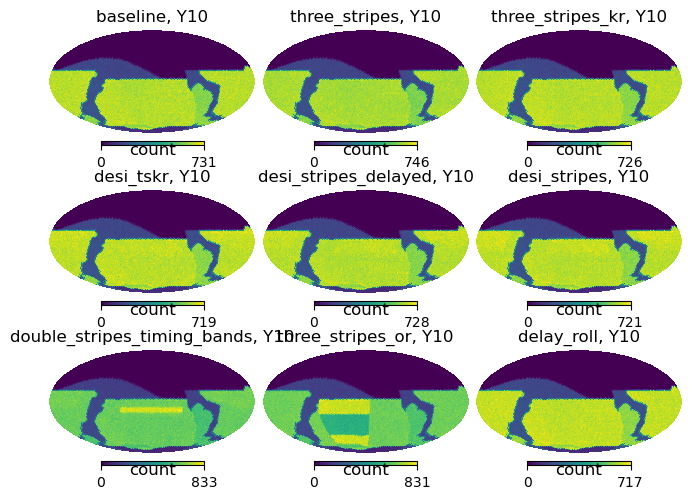

In [8]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*10], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y10",
                unit="count", sub=(3,3, i+1))

# Year 3 in u-band

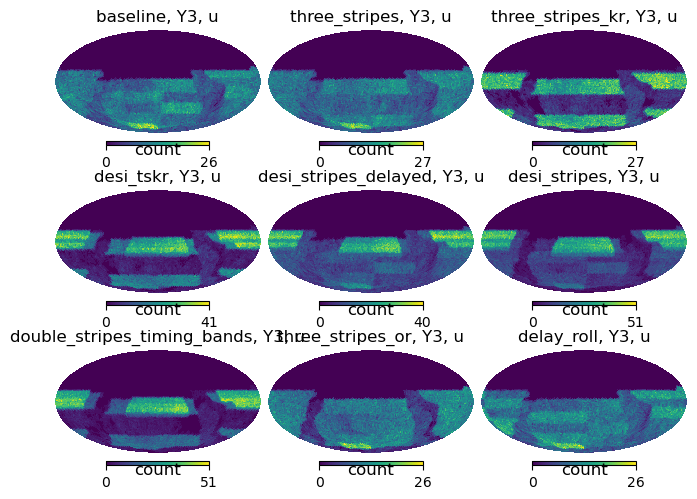

In [9]:
year = 3
for i, (data, info) in enumerate(zip(u_data_list, u_info_list)):
    hp.mollview(data[:,365*year], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y%i" % year + ', u',
                unit="count", sub=(3,3, i+1))

# Year 10 in u band

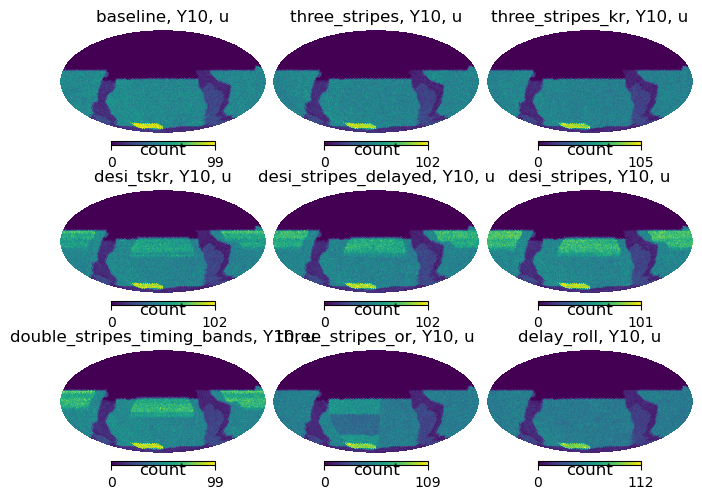

In [10]:
year = 10
for i, (data, info) in enumerate(zip(u_data_list, u_info_list)):
    hp.mollview(data[:,365*year], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y%i" % year + ', u',
                unit="count", sub=(3,3, i+1))

| run name<br>v5.3.7_10yrs | Rolling<br>Start | DESI<br>u Start | Template<br>Tier in Y1 | N Roll<br>Regions | Double<br>Roll Start | Uniform<br>Years |
| ------------------------ | ------------- | ------------ | ------------------- | -------------- | ----------------- | ---------------- |
| baseline                 | Y2            | No           | Yes                 | 4              | No                | 1,4,7,10         |
| three_stripes            | Y2            | No           | Yes                 | 3              | No                | 1,4,7,10         |
| three_stripes_kr         | Y1            | No           | No                  | 3              | Yes               | 6,9,10           |
| desi_tskr                | Y1            | Y2           | No                  | 3              | Yes               | 6,9,10           |
| desi_stripes_delayed     | Y2            | Y2           | Yes                 | 4              | No                | 1,4,7,10         |
| desi_stripes             | Y2            | Y1           | No                  | 4              | No                | 1,4,7,10         |
| double_stripes_timing_bands  |               |              |                     |                |                   |                  |
| three_stripes_or         |               |              |                     |                |                   |                  |
| delay_roll               |  Y3           |  No          | Yes                 | 4              | No                |                  |
|                          |               |              |                     |                |                   |                  |

Can potentially add an extra season of rolling and sacrifice a uniform year

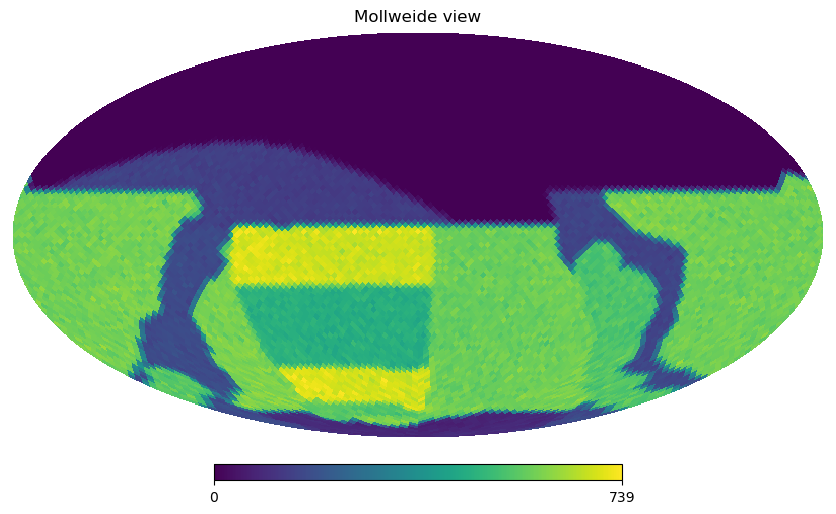

In [24]:
hp.mollview(data_list[-2][:,365*9])

In [25]:
ack = [ "1 1 U D 1 U D 1 U U 1 1 1 1 1 1 1 1 1",
        "1 1 D U 1 D U 1 D D 1 1 1 1 1 1 1 1 1",
        "1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1 1",
        "1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1 1",
        "1 1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1",
        "1 1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1",
        "1 1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1",
        "1 1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1",]

In [26]:
ack

['1 1 U D 1 U D 1 U U 1 1 1 1 1 1 1 1 1',
 '1 1 D U 1 D U 1 D D 1 1 1 1 1 1 1 1 1',
 '1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1 1',
 '1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1 1',
 '1 1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1',
 '1 1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1',
 '1 1 U D 1 U D 1 U D 1 1 1 1 1 1 1 1 1',
 '1 1 D U 1 D U 1 D U 1 1 1 1 1 1 1 1 1']